# 05 — Forecasts 12 months ahead, 80% intervals and the 2026/27 outlook

## Summary (Sprint 4: 12 months ahead)

**Up to 12 months ahead, the safest forecast is the average of "same month last year" and the model with FX. The model on its own loses to the naive at the longest horizons.** Every horizon is tested on the same 43 post-covid target months (Jan 2023 - Jul 2026); at h = 12 the earliest origin is Jan 2022.

| WAPE % (57 series) | Naive | Without FX | With FX | Naive + model with FX |
|---|---|---|---|---|
| h = 6 | 8.7 | 9.0 | 8.6 | 8.3 |
| h = 9 | 8.7 | 8.3 | 8.8 | 8.5 |
| h = 12 | 8.7 | 10.5 | 10.4 | 8.7 |
| h = 7-12 pooled | 8.7 | 8.8 | 9.0 | 8.4 |

- **Combination:** from 5 to 12 months ahead its WAPE stays between 8.2% and 8.7%. In peak season at h = 12 it scores 8.2% vs 8.5% for the naive.
- **Model with FX:** beats the naive at h = 1-8 and 10, not at h = 9, 11 or 12.
- **FX gain at h = 7-12:** negative in 4 of 6 horizons (descriptive only, no noise-floor test).
- **80% intervals, pre-set rule** (fitted on 2023-2024, checked on Jan 2025 - Jul 2026):
  - The combination's interval holds **84.7%** of actual months; 8 of 12 horizons fall in the 75-85% band (range 81.2-88.6%).
  - The model's interval holds 88.1%, so it is too wide.
  - By market, coverage is too low for the United States (74.5%) and China (74.2%), and too high for Switzerland (95.2%) and the United Kingdom (94.7%).
  - Median width (combination): 47% of the forecast at h = 1, 52% at h = 12.
- **Skewed upwards by 2023:** the q90 of the log error is 76.9% for 2023 vs 15.0-19.9% in 2024-2026; for China the median error in 2023 was +109.3%.
- **Decision taken after seeing these results:** 2023 was the tail of covid (post-covid rebound), so, like the covid exclusion in the change-point analysis, the intervals for forward-looking numbers (outlook, FX scenarios) are fitted on **Jan 2024 - Jul 2026 only**. Same check under this 2024+ rule (fitted on 2024 only): the combination holds **80.8%** (model 81.8%), 12 of 12 horizons in the 75-85% band, median width 33% at h = 1 and 37% at h = 12. The United Kingdom drops to 71.2%.
- **Totals are not calibrated.** Bounds summed month by month held the actual total in 100% of past 12-month windows and winters, under both rules, so they are too wide: read them as a wide range, not as an 80% interval.
- **Outlook from Jul 2026 (low confidence), 49 canton x origin series, 2024+ rule:**
  - **Next 12 months** (Aug 2026 - Jul 2027): 25.0 m nights, **+1.1%** vs a year earlier, wide range -9.1% to +15.5% (pre-set rule: -9.0% to +26.5%).
  - **Winter 2026/27** (Dec 2026 - Mar 2027): 8.4 m nights, **+1.0%**, wide range -9.0% to +14.8%.
  - Every market is between +0.5% and +4.1% over 12 months (China highest). China's upper bound is **+47.3%** (pre-set rule: +269.9%).

### Recommendation for hotels
For staffing and pricing plans 7-12 months ahead, use (naive + model with FX) / 2, not the model alone. Treat the outlook as "roughly flat, about +1%", with a wide, upward-skewed range.

Every number above is checked by the last code cell ("Summary check").


## Rules (fixed before the h = 7-12 results were computed)

- **Same model and rules as notebooks 03-04:** direct strategy, one model per horizon, FX feature = the market's currency at the forecast origin (lag = h), no look-ahead (scramble test at h = 12 in `run_long_horizon.py`), no tuning. `forecast.py` is unchanged; horizons 7-12 come from a scoped override (`long_horizon.horizons`), so the Sprint 3B cache stays valid.
- **Test months:** the same 43 post-covid target months (Jan 2023 - Jul 2026) for every horizon; origin = target - h, so at h = 12 the earliest origin is Jan 2022, the first month after covid.
- **Validation like Sprint 3A:** WAPE by horizon for the seasonal naive, the model without / with FX and both combinations (naive + model) / 2, overall and in peak season. The FX gain at h = 7-12 is **descriptive only** (no noise-floor test, unlike h = 1-6 in notebook 04).
- **80% prediction intervals** (no new model): 10th and 90th percentiles of the log error log(1 + actual) - log(1 + forecast) per horizon x market, for the model with FX and for (naive + model with FX) / 2. **Coverage check:** percentiles fitted on 2023-2024 target months, coverage measured on Jan 2025 - Jul 2026. Coverage counts as **close to nominal if it is between 75% and 85%**. The intervals used for the outlook were to be re-fitted on all 43 months.
- **Totals** (12 months, winter): bounds are the sums of the monthly bounds, which assumes the months' errors move together (a wide, conservative choice). Checked on 32 past 12-month windows and 3 past winters.
- **Outlook** from the Jul 2026 origin: next 12 months (Aug 2026 - Jul 2027) and winter 2026/27 (Dec 2026 - Mar 2027, h = 5-8). **Headline forecast: (naive + model with FX) / 2**, the notebook 04 recommendation for calm FX periods; the model with FX is shown next to it. Labelled **low confidence**.
- Descriptive language only: nothing here measures a causal effect of the franc.

### Decision taken after seeing the results: forward-looking intervals fitted on 2024 onwards
The first run (pre-set rule) showed bounds skewed upwards by the 2023 errors (section 3). 2023 was the tail of covid: demand was still rebounding and actuals were far above forecasts, China above all. **After seeing these results** we decided to fit the intervals used for forward-looking numbers (the outlook and `fx_scenarios`) on **Jan 2024 - Jul 2026 only** (31 target months), for the same reason the change-point analysis excludes the covid months. This is a post-hoc choice, so the backtest coverage check is kept **under the original pre-set rule** (fitted on 2023-2024), and coverage under the 2024+ rule (fitted on 2024 only, checked on the same Jan 2025 - Jul 2026 months) is shown next to it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import GREY, INK, INK_SOFT, ORIGIN_COLORS, SLOTS, SOURCE_BFS_SNB, add_source, connect, save, set_style
import forecast as fc
import long_horizon as lh
import outlook as ol

set_style()
pd.set_option("display.precision", 2)
con = connect()
panel, fx = fc.load_panel(con), fc.load_fx_yoy(con)
con.close()

res = ol.load_backtest(panel)          # asserts both cache fingerprints
ALL = list(fc.MODELS) + list(fc.COMBOS)
NAMES = {**fc.MODELS, **fc.COMBOS}
MARKET_ORDER = ["Switzerland", "Germany", "France", "Italy", "United Kingdom", "United States", "China", "Resort totals"]
short = fc.wape_table(res[res["h"] <= 6], []).iloc[0]
assert (round(short.naive, 2), round(short.gb_no_fx, 2), round(short.gb_fx, 2)) == (8.74, 8.33, 8.17)
print(f"{len(res):,} forecasts | {res['series_id'].nunique()} series | h = 1..12; h = 1-6 reproduce notebook 03")

29,412 forecasts | 57 series | h = 1..12; h = 1-6 reproduce notebook 03


## 1. Test months per horizon

In [2]:
months = res.groupby("h").agg(target_months=("target_date", "nunique"), forecasts=("actual", "size"),
                              first_origin=("origin_date", "min"), last_origin=("origin_date", "max"))
months["first_origin"] = months["first_origin"].dt.strftime("%Y-%m")
months["last_origin"] = months["last_origin"].dt.strftime("%Y-%m")
display(months)
print(f"Every horizon is tested on {months['target_months'].min()}-{months['target_months'].max()} target months; "
      f"earliest origin at h = 12: {months.loc[12, 'first_origin']}")

,target_months,forecasts,first_origin,last_origin
h,,,,
1,43,2451,2022-12,2026-06
2,43,2451,2022-11,2026-05
3,43,2451,2022-10,2026-04
4,43,2451,2022-09,2026-03
5,43,2451,2022-08,2026-02
6,43,2451,2022-07,2026-01
7,43,2451,2022-06,2025-12
8,43,2451,2022-05,2025-11
9,43,2451,2022-04,2025-10


Every horizon is tested on 43-43 target months; earliest origin at h = 12: 2022-01


## 2. WAPE by horizon (h = 1-12)

In [3]:
wh = fc.wape_table(res, ["h"], ALL).set_index("h")
wp = fc.wape_table(res[res["peak"]], ["h"], ALL).set_index("h")
wh["model_beats_naive"] = wh["gb_fx"] < wh["naive"]
wh["combo_fx_best"] = wh["combo_fx"] <= wh[ALL].min(axis=1)
display(pd.concat({"all months": wh, "peak season": wp}, axis=1).round(2))
for h in [6, 9, 12]:
    r = wh.loc[h]
    print(f"h = {h:>2}: naive {r.naive:.2f} | without FX {r.gb_no_fx:.2f} | with FX {r.gb_fx:.2f} | "
          f"naive + model with FX {r.combo_fx:.2f} | FX gain {r.fx_gain:+.2f}")
long = fc.wape_table(res[res["h"] >= 7], [], ALL).iloc[0]
print(f"h = 7-12 pooled: naive {long.naive:.2f} | without FX {long.gb_no_fx:.2f} | with FX {long.gb_fx:.2f} | "
      f"combo with FX {long.combo_fx:.2f}")
print("Horizons where the model with FX beats the naive:", wh.index[wh["model_beats_naive"]].tolist())
print("Horizons where naive + model with FX is the best of the five:", wh.index[wh["combo_fx_best"]].tolist())

all months                                                     \
        naive gb_no_fx  gb_fx combo_no_fx combo_fx fx_gain     n   
h                                                                  
1        8.74     7.44   7.44        7.78     7.81    0.00  2451   
2        8.74     8.28   7.97        7.96     7.89    0.32  2451   
3        8.74     8.27   8.30        8.00     8.02   -0.03  2451   
4        8.74     8.33   8.24        8.12     8.13    0.08  2451   
5        8.74     8.67   8.47        8.31     8.16    0.20  2451   
6        8.74     9.01   8.61        8.57     8.28    0.40  2451   
7        8.74     8.73   8.52        8.45     8.30    0.21  2451   
8        8.74     8.56   8.67        8.30     8.31   -0.11  2451   
9        8.74     8.32   8.80        8.25     8.48   -0.48  2451   
10       8.74     8.10   8.51        8.12     8.28   -0.41  2451   
11       8.74     8.50   8.84        8.24     8.36   -0.33  2451   
12       8.74    10.46  10.39        8.78     8.71    0.06  2451   

                                   peak season                              \
   model_beats_naive combo_fx_best       naive gb_no_fx  gb_fx combo_no_fx   
h                                                                            
1               True         False        8.47     7.56   7.42        7.77   
2               True          True        8.47     8.50   8.08        7.97   
3               True         False        8.47     8.14   8.14        7.83   
4               True         False        8.47     8.04   8.01        7.89   
5               True          True        8.47     8.63   8.46        8.11   
6               True          True        8.47     9.46   8.60        8.68   
7               True          True        8.47     8.85   8.45        8.44   
8               True         False        8.47     8.47   8.44        8.09   
9              False         False        8.47     7.96   8.60        7.90   
10              True         False        8.47     7.77   8.24        7.75   
11             False         False        8.47     8.18   8.53        7.78   
12             False          True        8.47    10.30  10.14        8.34   

                          
   combo_fx fx_gain    n  
h                         
1      7.75    0.14  613  
2      7.82    0.42  613  
3      7.85   -0.00  613  
4      7.92    0.03  613  
5      7.92    0.17  613  
6      8.10    0.86  613  
7      8.20    0.40  613  
8      8.05    0.03  613  
9      8.21   -0.64  613  
10     7.98   -0.47  613  
11     7.95   -0.35  613  
12     8.16    0.16  613

h =  6: naive 8.74 | without FX 9.01 | with FX 8.61 | naive + model with FX 8.28 | FX gain +0.40
h =  9: naive 8.74 | without FX 8.32 | with FX 8.80 | naive + model with FX 8.48 | FX gain -0.48
h = 12: naive 8.74 | without FX 10.46 | with FX 10.39 | naive + model with FX 8.71 | FX gain +0.06
h = 7-12 pooled: naive 8.74 | without FX 8.78 | with FX 8.95 | combo with FX 8.41
Horizons where the model with FX beats the naive: [1, 2, 3, 4, 5, 6, 7, 8, 10]
Horizons where naive + model with FX is the best of the five: [2, 5, 6, 7, 12]


In [4]:
w12 = fc.wape_table(res[res["h"] == 12], ["market"], ALL).set_index("market").reindex(MARKET_ORDER)
display(w12.round(2))

,naive,gb_no_fx,gb_fx,combo_no_fx,combo_fx,fx_gain,n
market,,,,,,,
Switzerland,6.21,7.73,7.29,6.69,6.51,0.44,301
Germany,9.62,12.57,11.84,10.80,10.35,0.72,301
France,8.04,9.31,9.57,8.38,8.43,-0.25,301
Italy,11.71,13.61,13.45,12.32,12.30,0.17,301
United Kingdom,13.65,17.52,16.46,13.88,13.90,1.05,301
United States,13.65,13.54,15.78,10.25,10.92,-2.24,301
China,34.24,42.10,46.14,32.57,33.47,-4.04,301
Resort totals,8.00,9.31,8.94,8.34,8.15,0.37,344


## 3. 80% prediction intervals: coverage on Jan 2025 - Jul 2026 (pre-set rule: fitted on 2023-2024)

In [5]:
q_cal = ol.interval_quantiles(res, "check_preset")      # pre-set coverage check: fitted on 2023-2024
q_all = ol.interval_quantiles(res, "preset")            # pre-set rule for the outlook: all 43 months
q_c24 = ol.interval_quantiles(res, "check_2024")        # 2024+ rule, coverage check: fitted on 2024
q_fwd = ol.interval_quantiles(res, "forward")           # 2024+ rule for the outlook: Jan 2024 - Jul 2026
ev = ol.with_intervals(res[res["target_date"] >= lh.EVAL_START], q_cal)
print(f"calibration: {res[res['target_date'] <= lh.CALIB_END]['target_date'].nunique()} target months | "
      f"check: {ev['target_date'].nunique()} target months, {len(ev):,} forecasts")

def cov(df, by):
    a = lh.coverage(df, by).rename(columns={"coverage": "model_fx"})
    b = lh.coverage(df, by, "combo_lower_80", "combo_upper_80").rename(columns={"coverage": "combo_fx"})
    return a.merge(b.drop(columns="n"), on=by) if by else a.assign(combo_fx=b["combo_fx"])

cov_all = cov(ev, [])
cov_h = cov(ev, ["h"]).set_index("h")
cov_m = cov(ev, ["market"]).set_index("market").reindex(MARKET_ORDER)
cov_peak = cov(ev[ev["peak"]], [])
display(cov_h.round(1)); display(cov_m.round(1))
c = cov_all.iloc[0]; cp = cov_peak.iloc[0]
close = lambda x: 75 <= x <= 85
print(f"Overall coverage: model with FX {c.model_fx:.1f}%, combination {c.combo_fx:.1f}% (nominal 80%) | "
      f"peak season {cp.model_fx:.1f}% / {cp.combo_fx:.1f}%")
print(f"Horizons close to nominal (75-85%): model {int(cov_h['model_fx'].map(close).sum())}/12, "
      f"combination {int(cov_h['combo_fx'].map(close).sum())}/12 | coverage range by horizon "
      f"{cov_h['combo_fx'].min():.1f}-{cov_h['combo_fx'].max():.1f}% (combination)")
width = ev.assign(w=100 * (ev["combo_upper_80"] - ev["combo_lower_80"]) / ev["combo_fx"])
width_h = width.groupby("h")["w"].median()
print(f"Median interval width (combination), % of the forecast: h = 1 {width_h[1]:.0f}%, h = 6 {width_h[6]:.0f}%, "
      f"h = 12 {width_h[12]:.0f}%")

calibration: 24 target months | check: 19 target months, 12,996 forecasts


,model_fx,n,combo_fx
h,,,
1,84.1,1083,81.2
2,88.6,1083,84.0
3,89.4,1083,84.0
4,87.1,1083,83.8
5,89.7,1083,87.0
6,88.6,1083,85.8
7,88.6,1083,86.5
8,87.3,1083,84.2
9,87.6,1083,83.3


,model_fx,n,combo_fx
market,,,
Switzerland,94.7,1596,95.2
Germany,88.9,1596,89.6
France,87.0,1596,82.7
Italy,91.4,1596,90.4
United Kingdom,93.5,1596,94.7
United States,86.2,1596,74.5
China,86.7,1596,74.2
Resort totals,78.0,1824,77.0


Overall coverage: model with FX 88.1%, combination 84.7% (nominal 80%) | peak season 88.3% / 84.7%
Horizons close to nominal (75-85%): model 1/12, combination 8/12 | coverage range by horizon 81.2-88.6% (combination)
Median interval width (combination), % of the forecast: h = 1 47%, h = 6 45%, h = 12 52%


### Same check under the 2024+ rule (decided after seeing the results)

Fitted on the 12 target months of 2024 only, checked on the same Jan 2025 - Jul 2026 months. Fewer months to fit on, so the percentiles are noisier.

In [6]:
ev24 = ol.with_intervals(res[res["target_date"] >= lh.EVAL_START], q_c24)
c24 = cov(ev24, []).iloc[0]
cov_h24 = cov(ev24, ["h"]).set_index("h")
cov_m24 = cov(ev24, ["market"]).set_index("market").reindex(MARKET_ORDER)
cmp_m = pd.concat({"pre-set (2023-2024)": cov_m[["model_fx", "combo_fx"]], "2024+ (2024)": cov_m24[["model_fx", "combo_fx"]]}, axis=1)
display(cmp_m.round(1))
width24 = ev24.assign(w=100 * (ev24["combo_upper_80"] - ev24["combo_lower_80"]) / ev24["combo_fx"]).groupby("h")["w"].median()
print(f"Overall coverage, 2024+ rule: model with FX {c24.model_fx:.1f}%, combination {c24.combo_fx:.1f}% "
      f"(pre-set rule: {c.model_fx:.1f}% / {c.combo_fx:.1f}%)")
print(f"Horizons close to nominal (75-85%), combination: {int(cov_h24['combo_fx'].map(close).sum())}/12 "
      f"(pre-set rule: {int(cov_h['combo_fx'].map(close).sum())}/12) | range by horizon "
      f"{cov_h24['combo_fx'].min():.1f}-{cov_h24['combo_fx'].max():.1f}%")
print(f"Median width (combination): h = 1 {width24[1]:.0f}%, h = 12 {width24[12]:.0f}% "
      f"(pre-set rule: {width_h[1]:.0f}% / {width_h[12]:.0f}%)")

pre-set (2023-2024)          2024+ (2024)         
                          model_fx combo_fx     model_fx combo_fx
market                                                           
Switzerland                   94.7     95.2         94.2     94.2
Germany                       88.9     89.6         87.8     88.5
France                        87.0     82.7         82.8     78.4
Italy                         91.4     90.4         82.0     78.6
United Kingdom                93.5     94.7         71.7     71.2
United States                 86.2     74.5         78.4     75.3
China                         86.7     74.2         81.1     82.6
Resort totals                 78.0     77.0         77.0     78.5

Overall coverage, 2024+ rule: model with FX 81.8%, combination 80.8% (pre-set rule: 88.1% / 84.7%)
Horizons close to nominal (75-85%), combination: 12/12 (pre-set rule: 8/12) | range by horizon 78.9-84.3%
Median width (combination): h = 1 33%, h = 12 37% (pre-set rule: 47% / 52%)


### Totals: 12-month windows and winters from one origin

In [7]:
COLS = ["actual", "combo_fx", "combo_lower_80", "combo_upper_80"]
bt_all, bt_cal, bt_c24 = ol.with_intervals(res, q_all), ol.with_intervals(res, q_cal), ol.with_intervals(res, q_c24)

def totals(bt, origins, months_of, by):
    parts = [lh.window_totals(bt[bt["origin_date"] == o], "origin_date", months_of(o), by, COLS) for o in origins]
    t = pd.concat(parts, ignore_index=True)
    t["inside"] = t["actual"].between(t["combo_lower_80"], t["combo_upper_80"])
    return t

next12 = lambda o: pd.date_range(o + pd.DateOffset(months=1), periods=12, freq="MS")
winter = lambda o: pd.date_range(pd.Timestamp(o.year, 12, 1), periods=4, freq="MS")
o12_all = pd.date_range("2022-12-01", "2025-07-01", freq="MS")
o12_oos = pd.date_range("2024-12-01", "2025-07-01", freq="MS")
ow_all = pd.to_datetime(["2023-07-01", "2024-07-01", "2025-07-01"])
ow_oos = pd.to_datetime(["2025-07-01"])
tot_rows = []
for name, bt, origins, fn in [("12 months, in-sample", bt_all, o12_all, next12), ("12 months, out-of-sample", bt_cal, o12_oos, next12),
                              ("winter, in-sample", bt_all, ow_all, winter), ("winter, out-of-sample", bt_cal, ow_oos, winter),
                              ("12 months, out-of-sample, 2024+ rule", bt_c24, o12_oos, next12),
                              ("winter, out-of-sample, 2024+ rule", bt_c24, ow_oos, winter)]:
    t = totals(bt, origins, fn, ["market"])
    tot_rows.append({"check": name, "windows": len(origins), "market_totals": len(t),
                     "coverage_pct": 100 * t["inside"].mean(),
                     "median_width_pct": (100 * (t["combo_upper_80"] - t["combo_lower_80"]) / t["combo_fx"]).median()})
tot_cov = pd.DataFrame(tot_rows).set_index("check")
display(tot_cov.round(1))

,windows,market_totals,coverage_pct,median_width_pct
check,,,,
"12 months, in-sample",32,256,100.0,40.7
"12 months, out-of-sample",8,64,100.0,47.6
"winter, in-sample",3,24,100.0,41.2
"winter, out-of-sample",1,8,100.0,48.1
"12 months, out-of-sample, 2024+ rule",8,64,100.0,34.1
"winter, out-of-sample, 2024+ rule",1,8,100.0,32.9


Why are the bounds skewed upwards? Percentiles of the log error of the combination, by target year (in %):

In [8]:
err = res.assign(e=100 * lh.log_error(res["actual"], res["combo_fx"]), year=res["target_date"].dt.year)
skew = err.groupby("year")["e"].quantile([lh.Q_LO, 0.5, lh.Q_HI]).unstack()
skew.columns = ["q10", "median", "q90"]
skew_cn = err[err["market"] == "China"].groupby("year")["e"].quantile([lh.Q_LO, 0.5, lh.Q_HI]).unstack()
skew_cn.columns = ["q10", "median", "q90"]
display(pd.concat({"all series": skew, "China": skew_cn}, axis=1).round(1))
print(f"2023 (post-covid rebound): q90 {skew.loc[2023, 'q90']:.1f}% vs {skew.loc[2024:, 'q90'].min():.1f}-"
      f"{skew.loc[2024:, 'q90'].max():.1f}% in 2024-2026; China median {skew_cn.loc[2023, 'median']:+.1f}% in 2023, "
      f"q90 {skew_cn.loc[2023, 'q90']:.1f}% vs {skew_cn.loc[2024:, 'q90'].max():.1f}% at most later")

all series              China              
            q10 median   q90   q10 median    q90
year                                            
2023      -12.4    7.9  76.9  42.7  109.3  174.6
2024      -19.7    1.3  19.9 -41.4   -2.0   55.7
2025      -15.7    2.4  18.5 -50.7   -2.3   22.9
2026      -16.1    0.5  15.0 -49.2  -12.4   31.4

2023 (post-covid rebound): q90 76.9% vs 15.0-19.9% in 2024-2026; China median +109.3% in 2023, q90 174.6% vs 55.7% at most later


## 4. Outlook from the Jul 2026 origin (low confidence)

Intervals: 2024+ rule (fitted on Jan 2024 - Jul 2026, decided after seeing the results). The pre-set rule (all 43 months) is shown at the end for comparison.

In [9]:
models = lh.forecast_from_origin(panel, fx)
out = ol.build_outlook(panel, fx, q_fwd, models)
out_pre = ol.build_outlook(panel, fx, q_all, models)

def prev_actual(months):
    p = panel[panel["date"].isin(months)].copy()
    p["market"] = np.where(p["level"] == "resort", "Resort totals", p["origin"])
    return p

def outlook_table(sub, prev, by):
    t = sub.groupby(by)[["combo_fx", "combo_lower_80", "combo_upper_80", "gb_fx"]].sum()
    t["last_year"] = prev.groupby(by)["nights"].sum()
    for c in ["combo_fx", "combo_lower_80", "combo_upper_80", "gb_fx"]:
        t[f"{c}_vs_ly_pct"] = 100 * (t[c] / t["last_year"] - 1)
    return t

m12 = pd.date_range("2025-08-01", "2026-07-01", freq="MS")
mw = pd.date_range("2025-12-01", "2026-03-01", freq="MS")
canton_out, canton_prev12, canton_prevw = out[out["level"] == "canton"], prev_actual(m12), prev_actual(mw)
o_m12 = outlook_table(out, prev_actual(m12), "market").reindex(MARKET_ORDER)
o_mw = outlook_table(out[out["in_winter"]], prev_actual(mw), "market").reindex(MARKET_ORDER)
o_c12 = outlook_table(canton_out, canton_prev12[canton_prev12["level"] == "canton"], "geo")
o_cw = outlook_table(canton_out[canton_out["in_winter"]], canton_prevw[canton_prevw["level"] == "canton"], "geo")
show = ["last_year", "combo_fx", "combo_lower_80", "combo_upper_80", "combo_fx_vs_ly_pct", "combo_lower_80_vs_ly_pct",
        "combo_upper_80_vs_ly_pct", "gb_fx_vs_ly_pct"]
for title, t in [("Next 12 months by market", o_m12), ("Winter 2026/27 by market", o_mw),
                 ("Next 12 months by canton (canton x origin series)", o_c12), ("Winter 2026/27 by canton", o_cw)]:
    print(title); display(t[show].round(1))
ct = canton_out.copy()
tot12 = {c: ct[c].sum() for c in ["combo_fx", "combo_lower_80", "combo_upper_80"]}
ly12 = canton_prev12.loc[canton_prev12["level"] == "canton", "nights"].sum()
totw = {c: ct.loc[ct["in_winter"], c].sum() for c in ["combo_fx", "combo_lower_80", "combo_upper_80"]}
lyw = canton_prevw.loc[canton_prevw["level"] == "canton", "nights"].sum()
pct = lambda x, ly: 100 * (x / ly - 1)
print(f"7 cantons, 7 markets, next 12 months: {tot12['combo_fx']/1e6:.1f} m nights "
      f"({pct(tot12['combo_fx'], ly12):+.1f}% vs Aug 2025 - Jul 2026; wide range "
      f"{pct(tot12['combo_lower_80'], ly12):+.1f}% to {pct(tot12['combo_upper_80'], ly12):+.1f}%)")
print(f"Winter 2026/27: {totw['combo_fx']/1e6:.1f} m nights ({pct(totw['combo_fx'], lyw):+.1f}% vs Dec 2025 - Mar 2026; "
      f"wide range {pct(totw['combo_lower_80'], lyw):+.1f}% to {pct(totw['combo_upper_80'], lyw):+.1f}%)")

Next 12 months by market


,last_year,combo_fx,combo_lower_80,combo_upper_80,combo_fx_vs_ly_pct,combo_lower_80_vs_ly_pct,combo_upper_80_vs_ly_pct,gb_fx_vs_ly_pct
market,,,,,,,,
Switzerland,1.49e+07,1.51e+07,1.38e+07,1.67e+07,0.7,-7.5,11.6,1.5
Germany,2.63e+06,2.65e+06,2.32e+06,3.14e+06,0.5,-11.8,19.3,1.1
France,1.23e+06,1.24e+06,1.13e+06,1.44e+06,0.8,-8.4,17.2,1.6
Italy,5.90e+05,5.93e+05,5.11e+05,7.22e+05,0.6,-13.3,22.5,1.2
United Kingdom,1.44e+06,1.44e+06,1.20e+06,1.67e+06,0.6,-16.5,16.7,1.3
United States,3.23e+06,3.32e+06,3.04e+06,3.92e+06,2.8,-5.9,21.6,5.7
China,6.47e+05,6.74e+05,4.25e+05,9.53e+05,4.1,-34.3,47.3,8.2
Resort totals,2.66e+06,2.67e+06,2.13e+06,3.55e+06,0.6,-19.7,33.8,1.2


Winter 2026/27 by market


,last_year,combo_fx,combo_lower_80,combo_upper_80,combo_fx_vs_ly_pct,combo_lower_80_vs_ly_pct,combo_upper_80_vs_ly_pct,gb_fx_vs_ly_pct
market,,,,,,,,
Switzerland,5.27e+06,5.30e+06,4.86e+06,5.87e+06,0.7,-7.7,11.5,1.4
Germany,9.56e+05,9.61e+05,8.45e+05,1.13e+06,0.5,-11.6,18.7,1.1
France,4.06e+05,4.11e+05,3.74e+05,4.77e+05,1.1,-8.0,17.4,2.1
Italy,2.21e+05,2.22e+05,1.91e+05,2.70e+05,0.6,-13.5,22.4,1.2
United Kingdom,5.47e+05,5.49e+05,4.53e+05,6.31e+05,0.4,-17.0,15.5,0.8
United States,7.64e+05,7.92e+05,7.34e+05,9.44e+05,3.7,-4.0,23.5,7.3
China,1.31e+05,1.38e+05,8.64e+04,1.85e+05,4.9,-34.1,40.9,9.9
Resort totals,1.20e+06,1.21e+06,9.61e+05,1.62e+06,0.8,-19.7,35.2,1.6


Next 12 months by canton (canton x origin series)


,last_year,combo_fx,combo_lower_80,combo_upper_80,combo_fx_vs_ly_pct,combo_lower_80_vs_ly_pct,combo_upper_80_vs_ly_pct,gb_fx_vs_ly_pct
geo,,,,,,,,
Bern,4.60e+06,4.66e+06,4.17e+06,5.35e+06,1.3,-9.5,16.2,2.6
Geneva,2.43e+06,2.46e+06,2.19e+06,2.85e+06,1.2,-10.1,17.1,2.4
Graubünden,4.91e+06,4.93e+06,4.46e+06,5.56e+06,0.4,-9.0,13.4,0.8
Lucerne,1.82e+06,1.85e+06,1.65e+06,2.14e+06,1.4,-9.3,17.2,2.7
Valais,3.61e+06,3.64e+06,3.29e+06,4.12e+06,0.9,-8.7,14.3,1.7
Vaud,2.46e+06,2.49e+06,2.25e+06,2.83e+06,1.3,-8.5,15.2,2.6
Zurich,4.88e+06,4.95e+06,4.44e+06,5.69e+06,1.4,-9.1,16.6,2.7


Winter 2026/27 by canton


,last_year,combo_fx,combo_lower_80,combo_upper_80,combo_fx_vs_ly_pct,combo_lower_80_vs_ly_pct,combo_upper_80_vs_ly_pct,gb_fx_vs_ly_pct
geo,,,,,,,,
Bern,1.27e+06,1.29e+06,1.16e+06,1.46e+06,1.3,-9.0,14.9,2.6
Geneva,7.39e+05,7.48e+05,6.65e+05,8.62e+05,1.2,-10.0,16.6,2.5
Graubünden,2.30e+06,2.31e+06,2.09e+06,2.61e+06,0.5,-9.1,13.6,1.1
Lucerne,4.28e+05,4.34e+05,3.89e+05,4.96e+05,1.3,-9.1,15.9,2.6
Valais,1.52e+06,1.53e+06,1.39e+06,1.73e+06,0.8,-8.7,14.1,1.6
Vaud,6.70e+05,6.78e+05,6.13e+05,7.67e+05,1.3,-8.4,14.6,2.5
Zurich,1.37e+06,1.39e+06,1.24e+06,1.59e+06,1.4,-8.9,16.2,2.9


7 cantons, 7 markets, next 12 months: 25.0 m nights (+1.1% vs Aug 2025 - Jul 2026; wide range -9.1% to +15.5%)
Winter 2026/27: 8.4 m nights (+1.0% vs Dec 2025 - Mar 2026; wide range -9.0% to +14.8%)


Pre-set rule vs 2024+ rule: the same central forecast, different bounds (12 months, % vs a year earlier).

In [10]:
o_m12_pre = outlook_table(out_pre, prev_actual(m12), "market").reindex(MARKET_ORDER)
cmp_o = pd.DataFrame({"forecast": o_m12["combo_fx_vs_ly_pct"],
                      "lower, pre-set": o_m12_pre["combo_lower_80_vs_ly_pct"], "upper, pre-set": o_m12_pre["combo_upper_80_vs_ly_pct"],
                      "lower, 2024+": o_m12["combo_lower_80_vs_ly_pct"], "upper, 2024+": o_m12["combo_upper_80_vs_ly_pct"]})
display(cmp_o.round(1))
pre_c = out_pre[out_pre["level"] == "canton"]
pre12 = {c: pre_c[c].sum() for c in ["combo_lower_80", "combo_upper_80"]}
print(f"China upper bound, next 12 months: {cmp_o.loc['China', 'upper, 2024+']:+.1f}% (2024+ rule) vs "
      f"{cmp_o.loc['China', 'upper, pre-set']:+.1f}% (pre-set rule)")
print(f"Total, next 12 months: range {pct(tot12['combo_lower_80'], ly12):+.1f}% to {pct(tot12['combo_upper_80'], ly12):+.1f}% "
      f"(2024+ rule) vs {pct(pre12['combo_lower_80'], ly12):+.1f}% to {pct(pre12['combo_upper_80'], ly12):+.1f}% (pre-set rule)")

,forecast,"lower, pre-set","upper, pre-set","lower, 2024+","upper, 2024+"
market,,,,,
Switzerland,0.7,-8.0,13.4,-7.5,11.6
Germany,0.5,-10.8,24.7,-11.8,19.3
France,0.8,-8.4,20.2,-8.4,17.2
Italy,0.6,-14.4,26.4,-13.3,22.5
United Kingdom,0.6,-14.8,33.6,-16.5,16.7
United States,2.8,-4.7,38.8,-5.9,21.6
China,4.1,-29.8,269.9,-34.3,47.3
Resort totals,0.6,-23.4,29.7,-19.7,33.8


China upper bound, next 12 months: +47.3% (2024+ rule) vs +269.9% (pre-set rule)
Total, next 12 months: range -9.1% to +15.5% (2024+ rule) vs -9.0% to +26.5% (pre-set rule)


### Chart 16 — WAPE by horizon, 1 to 12 months ahead

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/16_wape_by_horizon_12.png')

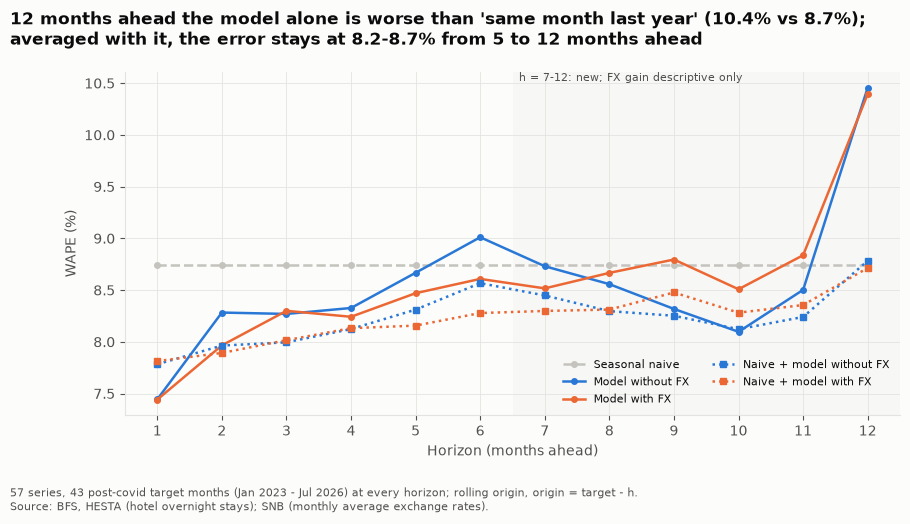

In [11]:
STYLE = {"naive": dict(color=GREY, ls="--"), "gb_no_fx": dict(color=SLOTS[0]), "gb_fx": dict(color=SLOTS[1]),
         "combo_no_fx": dict(color=SLOTS[0], ls=":", marker="s"), "combo_fx": dict(color=SLOTS[1], ls=":", marker="s")}
fig, ax = plt.subplots(figsize=(10, 5.2))
for col in ALL:
    ax.plot(wh.index, wh[col], lw=1.8, ms=4, label=NAMES[col], **{"marker": "o", **STYLE[col]})
ax.axvspan(6.5, 12.5, color=GREY, alpha=0.08, lw=0)
ax.text(6.6, ax.get_ylim()[1], "h = 7-12: new; FX gain descriptive only", va="top", fontsize=8, color=INK_SOFT)
ax.set_xticks(list(lh.HORIZONS_LONG)); ax.set_xlim(0.5, 12.5)
ax.set_xlabel("Horizon (months ahead)"); ax.set_ylabel("WAPE (%)")
ax.legend(fontsize=8, loc="lower right", ncol=2)
r12 = wh.loc[12]
cmb = wh.loc[5:12, "combo_fx"]
fig.suptitle(f"12 months ahead the model alone is worse than 'same month last year' ({r12.gb_fx:.1f}% vs {r12.naive:.1f}%);\n"
             f"averaged with it, the error stays at {cmb.min():.1f}-{cmb.max():.1f}% from 5 to 12 months ahead",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "57 series, 43 post-covid target months (Jan 2023 - Jul 2026) at every horizon; "
           "rolling origin, origin = target - h.")
fig.subplots_adjust(bottom=0.2, top=0.86)
save(fig, "16_wape_by_horizon_12")

### Chart 17 — Coverage of the 80% intervals by horizon

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/17_interval_coverage.png')

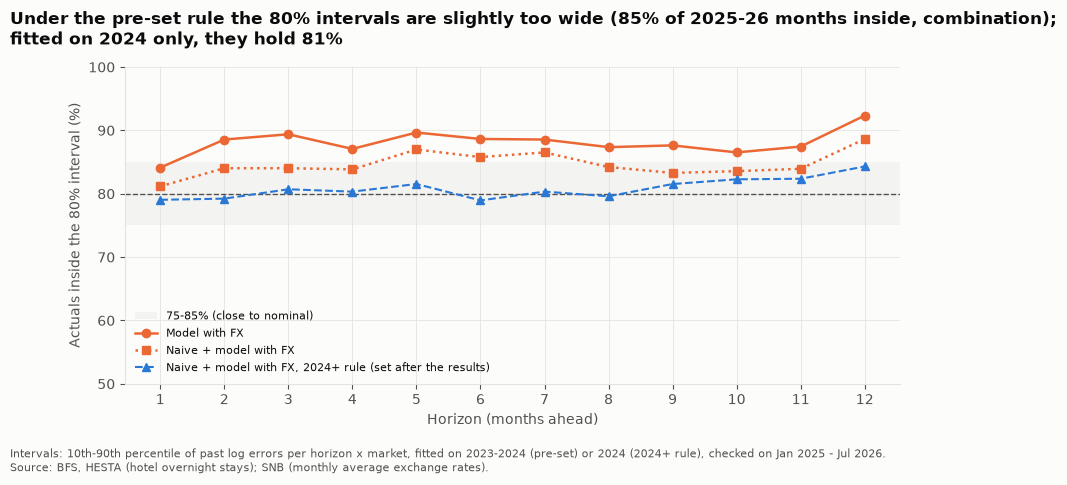

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axhspan(75, 85, color=GREY, alpha=0.15, lw=0, label="75-85% (close to nominal)")
ax.axhline(80, color=INK_SOFT, lw=1, ls="--")
ax.plot(cov_h.index, cov_h["model_fx"], marker="o", lw=1.8, color=SLOTS[1], label="Model with FX")
ax.plot(cov_h.index, cov_h["combo_fx"], marker="s", lw=1.8, ls=":", color=SLOTS[1], label="Naive + model with FX")
ax.plot(cov_h24.index, cov_h24["combo_fx"], marker="^", lw=1.5, ls="--", color=SLOTS[0],
        label="Naive + model with FX, 2024+ rule (set after the results)")
ax.set_xticks(list(lh.HORIZONS_LONG)); ax.set_ylim(50, 100)
ax.set_xlabel("Horizon (months ahead)"); ax.set_ylabel("Actuals inside the 80% interval (%)")
ax.legend(fontsize=8, loc="lower left")
fig.suptitle(f"Under the pre-set rule the 80% intervals are slightly too wide ({c.combo_fx:.0f}% of 2025-26 months inside, "
             f"combination);\nfitted on 2024 only, they hold {c24.combo_fx:.0f}%", x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Intervals: 10th-90th percentile of past log errors per horizon x market, "
           "fitted on 2023-2024 (pre-set) or 2024 (2024+ rule), checked on Jan 2025 - Jul 2026.")
fig.subplots_adjust(bottom=0.2, top=0.86)
save(fig, "17_interval_coverage")

### Chart 18 — Outlook by origin market vs the same months a year earlier

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/18_outlook_by_market.png')

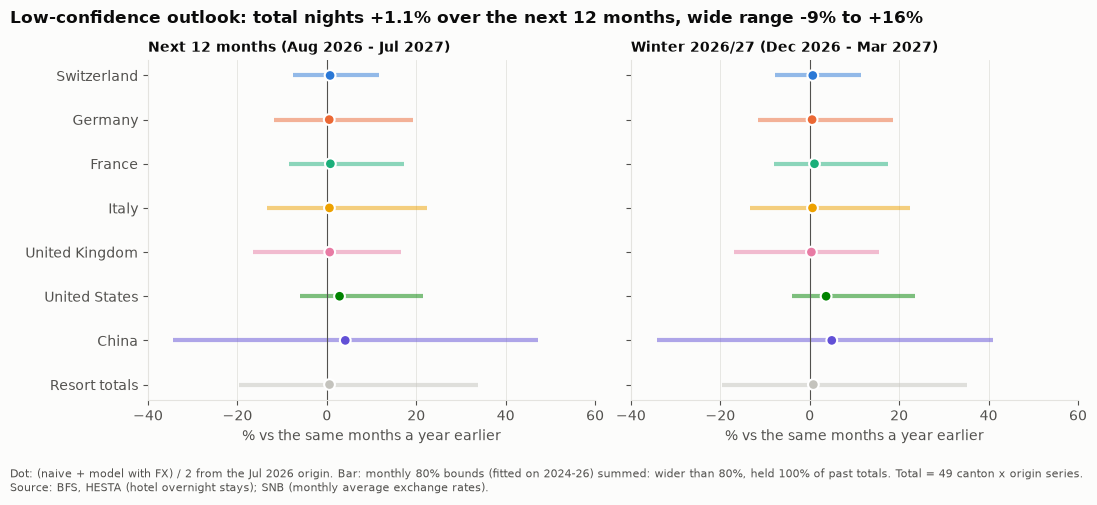

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
y = np.arange(len(MARKET_ORDER))[::-1]
for ax, (t, title) in zip(axes, [(o_m12, "Next 12 months (Aug 2026 - Jul 2027)"),
                                 (o_mw, "Winter 2026/27 (Dec 2026 - Mar 2027)")]):
    col = [GREY if m == "Resort totals" else ORIGIN_COLORS[m] for m in MARKET_ORDER]
    ax.hlines(y, t["combo_lower_80_vs_ly_pct"], t["combo_upper_80_vs_ly_pct"], color=col, lw=3, alpha=0.5)
    ax.scatter(t["combo_fx_vs_ly_pct"], y, color=col, s=60, zorder=3, edgecolor="white", linewidth=1.5)
    ax.axvline(0, color=INK_SOFT, lw=0.8)
    ax.set_yticks(y, MARKET_ORDER); ax.grid(axis="y", visible=False)
    XMAX = 60      # keeps the markets readable if an upper bound is very wide
    ax.set_xlim(-40, XMAX)
    for yy, (m, r) in zip(y, t.iterrows()):
        if r["combo_upper_80_vs_ly_pct"] > XMAX:
            ax.annotate(f"upper bound {r['combo_upper_80_vs_ly_pct']:+.0f}% →", xy=(XMAX, yy), xytext=(-4, 7),
                        textcoords="offset points", ha="right", fontsize=7, color=INK_SOFT)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("% vs the same months a year earlier")
fig.suptitle(f"Low-confidence outlook: total nights {pct(tot12['combo_fx'], ly12):+.1f}% over the next 12 months, "
             f"wide range {pct(tot12['combo_lower_80'], ly12):+.0f}% to {pct(tot12['combo_upper_80'], ly12):+.0f}%",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
cut = " Bars cut off at +60%." if (pd.concat([o_m12, o_mw])["combo_upper_80_vs_ly_pct"] > XMAX).any() else ""
add_source(fig, SOURCE_BFS_SNB + ".", "Dot: (naive + model with FX) / 2 from the Jul 2026 origin. Bar: monthly 80% bounds (fitted on 2024-26) "
           "summed: wider than 80%, held 100% of past totals." + cut + " Total = 49 canton x origin series.")
fig.subplots_adjust(bottom=0.2, top=0.88, wspace=0.08)
save(fig, "18_outlook_by_market")

## Limitations

- **One test period.** All 43 target months are post-covid (2023-2026), a recovery period; long horizons are tested on origins in 2022, when demand was still normalising.
- **FX at h = 7-12 is not tested against a noise floor** (notebook 04 did that for h = 1-6 only); the FX gain here is descriptive.
- **Post-hoc interval rule.** The forward-looking intervals leave out 2023, a choice made after seeing the results; they rest on 31 target months (2024 - Jul 2026) and assume 2024-2026 errors are typical. The coverage check under this rule is fitted on only 12 months (2024). Under the pre-set rule (all 43 months) the upper bounds are much wider.
- **Intervals come from past errors only.** They do not include FX scenarios, new shocks or data revisions, and they assume the error pattern of 2024-2026 carries on.
- **Coverage check is short:** 19 target months (Jan 2025 - Jul 2026); errors of overlapping forecasts are correlated.
- **Totals:** bounds summed month by month (wide by design); only 32 overlapping 12-month windows (≈ 2.7 independent years) and 3 winters to check them, of which 8 windows and 1 winter out of sample.
- **Outlook = low confidence.** Calendar 2027 is not forecast: Aug - Dec 2027 would be 13-17 months ahead of the Jul 2026 origin.
- **Hotels only;** overbooking and nightly pricing remain out of scope. Associations, not causal effects.

## Summary check

Every number in the summary at the top must match the results above.

In [14]:
f1 = lambda x: f"{x:.1f}"
row = lambda r: (f1(r.naive), f1(r.gb_no_fx), f1(r.gb_fx), f1(r.combo_fx))
t12 = tot_cov["coverage_pct"]
checks = {
    "43 months at every h, first origin h=12": months["target_months"].eq(43).all() and months.loc[12, "first_origin"] == "2022-01",
    "h=6 row": row(wh.loc[6]) == ('8.7', '9.0', '8.6', '8.3'),
    "h=9 row": row(wh.loc[9]) == ('8.7', '8.3', '8.8', '8.5'),
    "h=12 row": row(wh.loc[12]) == ('8.7', '10.5', '10.4', '8.7'),
    "h=7-12 pooled": row(long) == ('8.7', '8.8', '9.0', '8.4'),
    "combo 8.2-8.7 for h=5-12": (f1(wh.loc[5:12, "combo_fx"].min()), f1(wh.loc[5:12, "combo_fx"].max())) == ('8.2', '8.7'),
    "peak h=12 combo vs naive": (f1(wp.loc[12, "combo_fx"]), f1(wp.loc[12, "naive"])) == ('8.2', '8.5'),
    "model beats naive at h": wh.index[wh["model_beats_naive"]].tolist() == [1, 2, 3, 4, 5, 6, 7, 8, 10],
    "FX gain negative in 4/6 of h=7-12": int((wh.loc[7:12, "fx_gain"] < 0).sum()) == 4,
    "coverage combo / model": (f1(c.combo_fx), f1(c.model_fx)) == ('84.7', '88.1'),
    "8/12 horizons in band, range": int(cov_h["combo_fx"].map(close).sum()) == 8 and (f1(cov_h["combo_fx"].min()), f1(cov_h["combo_fx"].max())) == ('81.2', '88.6'),
    "market coverage US/CN/CH/UK": tuple(f1(cov_m.loc[m, "combo_fx"]) for m in ["United States", "China", "Switzerland", "United Kingdom"]) == ('74.5', '74.2', '95.2', '94.7'),
    "width h=1, h=12": (f"{width_h[1]:.0f}", f"{width_h[12]:.0f}") == ('47', '52'),
    "totals 100% covered": bool((t12 == 100).all()),
    "2023 skew": (f1(skew.loc[2023, "q90"]), f1(skew.loc[2024:, "q90"].min()), f1(skew.loc[2024:, "q90"].max()), f"{skew_cn.loc[2023, 'median']:+.1f}") == ('76.9', '15.0', '19.9', '+109.3'),
    "outlook 12m (2024+ rule)": (f1(tot12["combo_fx"] / 1e6), f"{pct(tot12['combo_fx'], ly12):+.1f}", f"{pct(tot12['combo_lower_80'], ly12):+.1f}", f"{pct(tot12['combo_upper_80'], ly12):+.1f}") == ('25.0', '+1.1', '-9.1', '+15.5'),
    "outlook 12m range, pre-set rule": (f"{pct(pre12['combo_lower_80'], ly12):+.1f}", f"{pct(pre12['combo_upper_80'], ly12):+.1f}") == ('-9.0', '+26.5'),
    "outlook winter": (f1(totw["combo_fx"] / 1e6), f"{pct(totw['combo_fx'], lyw):+.1f}", f"{pct(totw['combo_lower_80'], lyw):+.1f}", f"{pct(totw['combo_upper_80'], lyw):+.1f}") == ('8.4', '+1.0', '-9.0', '+14.8'),
    "China upper bound 2024+ / pre-set": (f"{cmp_o.loc['China', 'upper, 2024+']:+.1f}", f"{cmp_o.loc['China', 'upper, pre-set']:+.1f}") == ('+47.3', '+269.9'),
    "2024+ coverage combo / model": (f1(c24.combo_fx), f1(c24.model_fx)) == ('80.8', '81.8'),
    "2024+ 12/12 in band": int(cov_h24["combo_fx"].map(close).sum()) == 12,
    "2024+ width h=1, h=12": (f"{width24[1]:.0f}", f"{width24[12]:.0f}") == ('33', '37'),
    "2024+ UK coverage": f1(cov_m24.loc["United Kingdom", "combo_fx"]) == '71.2',
    "outlook uses 2024+ rule": np.allclose(out["combo_upper_80"], ol.with_intervals(out.drop(columns=["lower_80", "upper_80", "combo_lower_80", "combo_upper_80"]), ol.interval_quantiles(res, "forward"))["combo_upper_80"]),
    "markets +0.5 to +4.1, China highest": (f1(o_m12["combo_fx_vs_ly_pct"].min()), f1(o_m12["combo_fx_vs_ly_pct"].max())) == ('0.5', '4.1') and o_m12["combo_fx_vs_ly_pct"].idxmax() == "China",
}

for name, ok in checks.items():
    print(f"{'OK  ' if ok else 'FAIL'} {name}")
assert checks and all(checks.values()), "the summary at the top no longer matches the results"
print(sorted(p.name for p in (Path.cwd().resolve().parent / "reports" / "figures").glob("1[6-8]_*.png")))

OK   43 months at every h, first origin h=12
OK   h=6 row
OK   h=9 row
OK   h=12 row
OK   h=7-12 pooled
OK   combo 8.2-8.7 for h=5-12
OK   peak h=12 combo vs naive
OK   model beats naive at h
OK   FX gain negative in 4/6 of h=7-12
OK   coverage combo / model
OK   8/12 horizons in band, range
OK   market coverage US/CN/CH/UK
OK   width h=1, h=12
OK   totals 100% covered
OK   2023 skew
OK   outlook 12m (2024+ rule)
OK   outlook 12m range, pre-set rule
OK   outlook winter
OK   China upper bound 2024+ / pre-set
OK   2024+ coverage combo / model
OK   2024+ 12/12 in band
OK   2024+ width h=1, h=12
OK   2024+ UK coverage
OK   outlook uses 2024+ rule
OK   markets +0.5 to +4.1, China highest
['16_wape_by_horizon_12.png', '17_interval_coverage.png', '18_outlook_by_market.png']
